
## Excercise 2B Transfer Learning on HANDWRITTEN KMNIST
AUTHOR: AKINYI OCHOLLA

### Revisions:

* 2026-10-12
* AKINYI M. OCHOLLA

# First we initilize our Python environment

In [1]:
#### Set up tests to know if we are running Colab or Kaggle
import sys

### Is this notebook running on Colab?
IS_COLAB = "google.colab" in sys.modules

### Is this notebook running on Kaggle?
# Fool Kaggle into making kaggle_secrets avaiable
try:
    import kaggle_secrets
except ImportError as e:
    pass
# Now we can test for Kaggle
IS_KAGGLE = "kaggle_secrets" in sys.modules

In [2]:
# Set up Keras/Tensorflow framework
import os
os.environ["KERAS_BACKEND"] = "tensorflow" # Also tensorflow, jax, pytorch for Keras 3.0

import keras
print('Keras version:', keras.__version__)

# Import needed libraries
import tensorflow as tf
print('TensorFlow version:', tf.__version__)

2026-10-15 06:47:47.278203: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792046867.711847      49 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792046867.820556      49 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

Keras version: 3.8.0
TensorFlow version: 2.18.0


In [3]:
#### Additional helper libraries
import pandas as pd
import numpy as np
import time
import sklearn
import tensorflow_datasets as tfds
import tensorflow as tf

# Matlab plotting
import matplotlib
import matplotlib.pyplot as plt

In [4]:
# Test for GPU and determine what GPU we have
import platform
import subprocess
gpu_devices = tf.config.list_physical_devices('GPU')

gpu_name = tf.test.gpu_device_name()
if gpu_name != '':
    print('TF-GPU-devname:',tf.test.gpu_device_name())
    sys_details = tf.sysconfig.get_build_info()
    physical_devices = tf.config.list_physical_devices('GPU')
    print("Num GPUs:", len(physical_devices))
    if platform.system() == "Darwin":
        print('GPU on Mac!')
    else:
        cuda_version = sys_details["cuda_version"]
        print('TF-cuda version:',cuda_version)
        if len(physical_devices)>0:
            process = subprocess.Popen(['nvidia-smi','-L'], stdout=subprocess.PIPE, stderr=subprocess.PIPE)
            print(process.communicate())
        # If possible to run code with 16 bits float instead of 32 bits float, this code activates such functionality:
        if gpu_devices:
            details = tf.config.experimental.get_device_details(gpu_devices[0])
            compute_capability=details.get('compute_capability')
            print("Compute capability:",compute_capability)
            if compute_capability[0]>6:
                print("Turning on mixed_float16")
                policy = keras.mixed_precision.Policy('mixed_float16')
                keras.mixed_precision.set_global_policy(policy)
else:
    print('TF-device CPU')

TF-GPU-devname: /device:GPU:0
Num GPUs: 2
TF-cuda version: 12.5.1
(b'GPU 0: Tesla T4 (UUID: GPU-146bad17-cce5-db7c-e7b4-2b75c3dbf75a)\nGPU 1: Tesla T4 (UUID: GPU-01a6a57d-bcf6-a454-91ca-cec51813de2f)\n', b'')
Compute capability: (7, 5)
Turning on mixed_float16


I0000 00:00:1792046893.873198      49 gpu_device.cc:2022] Created device /device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792046893.875993      49 gpu_device.cc:2022] Created device /device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
I0000 00:00:1792046893.891904      49 gpu_device.cc:2022] Created device /device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792046893.893573      49 gpu_device.cc:2022] Created device /device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5



# **We will use a similar dataset from Hugging face that is a little more challenging but which does not take too long to load KMNIST 28 × 28 grayscale 10 classes 70,000 images Japanese characters**


In [5]:
# 1. LOAD KMNIST AS A TENSOR
# Tensors are better for exploring large pipelines. But pandas and matplotlib/sklearn may require conversion
(ds_train, ds_test), ds_info = tfds.load(
    "kmnist",
    split=["train", "test"],
    as_supervised=True,
    with_info=True
) # This loads the dataset as a tensor

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

I0000 00:00:1792046936.394012      49 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792046936.395649      49 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Shuffling /root/tensorflow_datasets/kmnist/incomplete.GL33J8_3.0.1/kmnist-train.tfrecord*...:   0%|          |…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/kmnist/incomplete.GL33J8_3.0.1/kmnist-test.tfrecord*...:   0%|          | …

Dataset kmnist downloaded and prepared to /root/tensorflow_datasets/kmnist/3.0.1. Subsequent calls will reuse this data.


In [6]:
# VIEW THE INFO
print(ds_info)

tfds.core.DatasetInfo(
    name='kmnist',
    full_name='kmnist/3.0.1',
    description="""
    Kuzushiji-MNIST is a drop-in replacement for the MNIST dataset (28x28 grayscale, 70,000 images), provided in the original MNIST format as well as a NumPy format. Since MNIST restricts us to 10 classes, we chose one character to represent each of the 10 rows of Hiragana when creating Kuzushiji-MNIST.
    """,
    homepage='http://codh.rois.ac.jp/kmnist/index.html.en',
    data_dir='/root/tensorflow_datasets/kmnist/3.0.1',
    file_format=tfrecord,
    download_size=20.26 MiB,
    dataset_size=31.76 MiB,
    features=FeaturesDict({
        'image': Image(shape=(28, 28, 1), dtype=uint8),
        'label': ClassLabel(shape=(), dtype=int64, num_classes=10),
    }),
    supervised_keys=('image', 'label'),
    disable_shuffling=False,
    nondeterministic_order=False,
    splits={
        'test': <SplitInfo num_examples=10000, num_shards=1>,
        'train': <SplitInfo num_examples=60000, num_shards

In [7]:
print(type(ds_train)) 
# The result is <class 'tensorflow.python.data.ops.prefetch_op._PrefetchDataset'> 
# which is a pipeline stream of images and labels. Not a numpy array


<class 'tensorflow.python.data.ops.prefetch_op._PrefetchDataset'>


In [8]:
# To take a sample of a tensor, use take.()
ds_train.take(10)

<_TakeDataset element_spec=(TensorSpec(shape=(28, 28, 1), dtype=tf.uint8, name=None), TensorSpec(shape=(), dtype=tf.int64, name=None))>

In [9]:
# Spliting the ds_train to train and val sets
train_ds, val_ds = keras.utils.split_dataset(
    ds_train,
    right_size=0.2,
    shuffle=True,
    seed=42
)

In [10]:
for image, label in train_ds.take(10):
    print(image.shape, label.numpy())
# We look at the image shape instead of the image because the image itself
# is a huge vector and is not visually appealing plus it 
# takes up a lot of space in the result window.


(28, 28, 1) 5
(28, 28, 1) 3
(28, 28, 1) 1
(28, 28, 1) 5
(28, 28, 1) 7
(28, 28, 1) 8
(28, 28, 1) 5
(28, 28, 1) 6
(28, 28, 1) 4
(28, 28, 1) 4


In [11]:
# for image, label in ds_train.take(1):
#    print(image)

# The image is a huge tensor and is not visually appealing plus it 
# takes up a lot of space in the result window.

# Once you have batched the images you can look at the images.

In [12]:
# See the categories
class_names = ds_info.features["label"].names

print(class_names)

['o', 'ki', 'su', 'tsu', 'na', 'ha', 'ma', 'ya', 're', 'wo']


In [13]:
#PREPARE FOR KERAS
def normalize(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

In [14]:
batch_size = 128

ds_train = (
    train_ds
    .map(normalize, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(10000)
    .batch(batch_size)
    .prefetch(tf.data.AUTOTUNE)
)

ds_val = (
    val_ds
    .batch(batch_size)
    .prefetch(tf.data.AUTOTUNE)
)

ds_test = (
    ds_test
    .map(normalize, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(batch_size)
    .prefetch(tf.data.AUTOTUNE)
)

In [15]:
print(ds_train.element_spec)
# (None, 28, 28, 1) means that the dataset is batched
# (28, 28, 1) means that the dataset is unbatched

(TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))


In [16]:
# the images are now batched and you could look at an image
# but it is simply a very big tensor that isnt visually appealing
# for images, labels in ds_train.take(1):
#    print(images[0])
#    print(labels[0])

In [17]:


# Define labels
class_names = ['o', 'ki', 'su', 'tsu', 'na',
               'ha', 'ma', 'ya', 're', 'wo']
num_classes = len(class_names)



Note that the training labels are an integer between 0 and 9, which is not very good as outputs (or inputs) for DL models. A better approach will be to use a one-hot encoding. We can convert our label vectors to one-hot encoded matrices by using [to_categorical](https://www.tensorflow.org/api_docs/python/tf/keras/utils/to_categorical) `keras.utils.to_categorical(train_labels)`.

In this Excercise we will achieve the same thing by using [SparseCategoricalCrossentropy](https://keras.io/api/losses/probabilistic_losses/#sparsecategoricalcrossentropy-class) as a loss function instead of the [CategoricalCrossentropy](https://keras.io/api/losses/probabilistic_losses/#categoricalcrossentropy-class). But note that for both cases we need our model to have as many output nodes as we have classes!

## Explore the data
It is always advised to take a look at the data, especially after applying various modifications like in ds_img_transform above. But now the data is in datasets and we need to grab a batch by using `dataset.take()`

In [18]:
print(ds_train.element_spec)
# (None, 28, 28, 1) means that the dataset is batched
# (28, 28, 1) means that the dataset is unbatched

(TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))


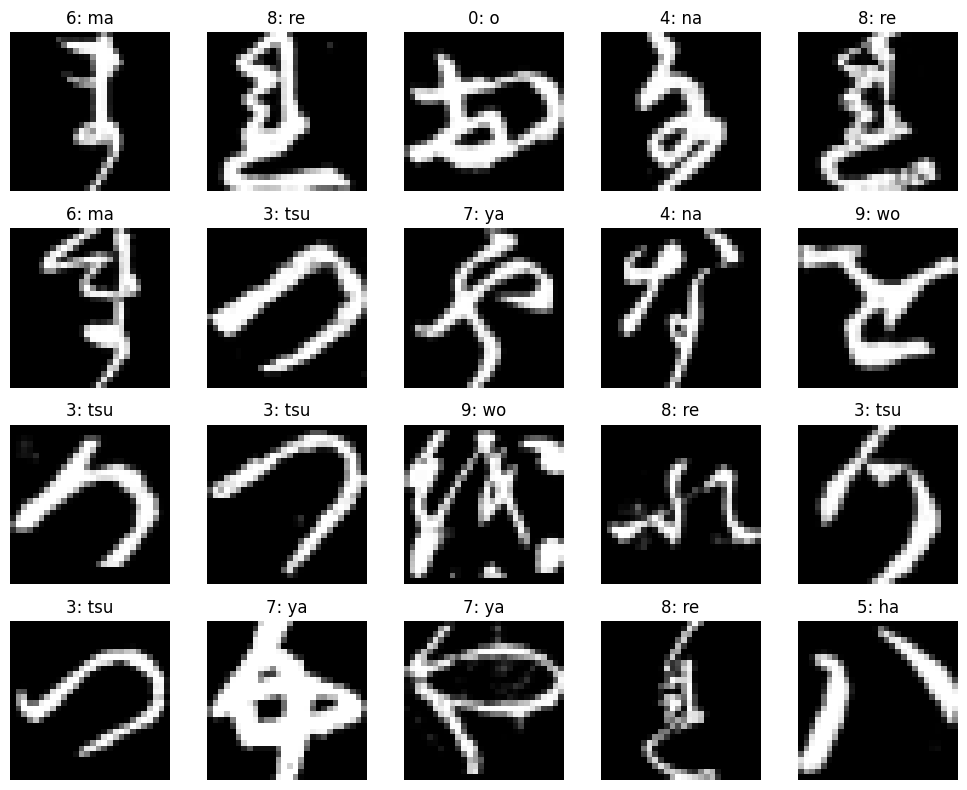

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

for images, labels in ds_train.take(1):
    for i in range(20):
        plt.subplot(4, 5, i + 1)

        plt.imshow(tf.squeeze(images[i]), cmap="gray")

        label = int(labels[i].numpy())
        plt.title(f"{label}: {class_names[label]}")

        plt.axis("off")

plt.tight_layout()
plt.show()

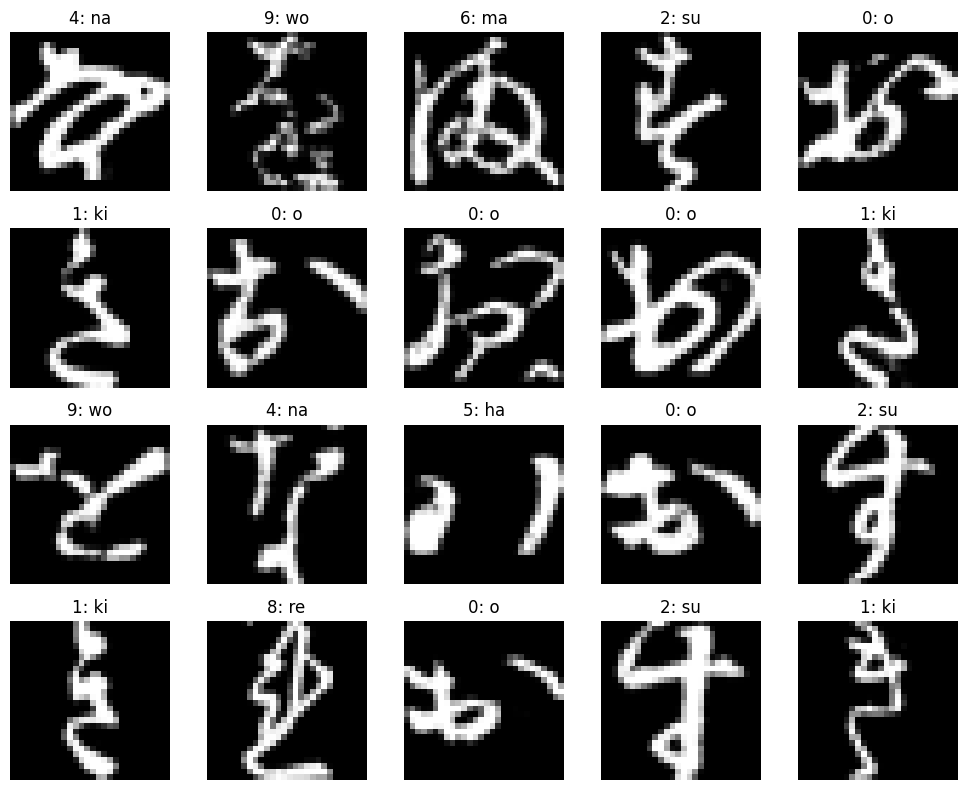

In [20]:
import matplotlib.pyplot as plt
import tensorflow as tf

plt.figure(figsize=(10, 8))

for images, labels in ds_train.take(1):
    number_to_show = min(20, images.shape[0])

    for i in range(number_to_show):
        plt.subplot(4, 5, i + 1)

        # images[i] is one image with shape (28, 28, 1)
        image_2d = tf.squeeze(images[i], axis=-1)

        plt.imshow(image_2d.numpy(), cmap="gray")

        label_id = int(labels[i].numpy())
        plt.title(f"{label_id}: {class_names[label_id]}")
        plt.axis("off")

plt.tight_layout()
plt.show()

# Transfer learning
Now follows the main topic of this exercise.
We shall do a comparison of MobileNetV2 and a CNN built from scratch. Why? Because the Pretrained model learned from ImageNet which contained natural RGB imagery (dogs, cats, birds, buildings, colours, textures, natural edges). KMNIST consists of grayscale japanese characters. Also KMNIST consists of 28x28x1 and MobileNetV2 images require 3 input channels. I.e. 28x28x1 -> 28x28x3 -> resize() -> 96x96x3 -> MobileNetV2 (this model supports any image of size 96x96 or larger)

## Read in the model to transfer
You can find the available models at [Keras Applications](https://keras.io/api/applications/)

For this excersize we will not use [VGG16](https://keras.io/api/applications/vgg/#vgg16-function). because it has several millions of parameters. There are other smaller and more modern architectures we can use e.g. ResNet50 (25.6 M parameters), MobileNetV2 (3.5M), EfficientNetB0 (5.3M) and DenseNet121 (8.1M)

Think about using the correct values of some of the input parameters:
* weights='imagenet' --- Since we want to use the weights pretrained on the imagenet
* include_top=False --- This is False, we anyway will replace the "top" with our own layers. Note that they call the layers closest to the output the top layers.
* input_shape= **???** --- Set it to the same shape as the pictures have!

**MobileNetV2 (3.5M)**

In [21]:
import gc
import tensorflow as tf
from tensorflow import keras

keras.backend.clear_session()
gc.collect()

0

In [22]:
# 1. LOAD KMNIST AS A TENSOR
# Tensors are better for exploring large pipelines. But pandas and matplotlib/sklearn may require conversion
(ds_train, ds_test), ds_info = tfds.load(
    "kmnist",
    split=["train", "test"],
    as_supervised=True,
    with_info=True
) # This loads the dataset as a tensor

In [23]:
# Spliting the ds_train to train and val sets
train_ds, val_ds = keras.utils.split_dataset(
    ds_train,
    right_size=0.2,
    shuffle=True,
    seed=42
)

In [24]:
import tensorflow as tf
import keras

IMG_SIZE = 96

def preprocess_mobilenet(image, label):

    # uint8 -> float32
    image = tf.cast(image, tf.float32)

    # (28, 28, 1) -> (28, 28, 3)
    image = tf.image.grayscale_to_rgb(image)

    # (28, 28, 3) -> (96, 96, 3)
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))

    # MobileNetV2 preprocessing
    image = keras.applications.mobilenet_v2.preprocess_input(image)

    return image, label

In [25]:
# We rebatch and preprocess the datasets
batch_size = 128

ds_train = (
    train_ds
    .map(preprocess_mobilenet,num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(10000, seed=42)
    .batch(batch_size)
    .prefetch(tf.data.AUTOTUNE)
)

ds_val = (
    val_ds
    .map(preprocess_mobilenet, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(batch_size)
    .prefetch(tf.data.AUTOTUNE)
)

ds_test = (
    ds_test
    .map(preprocess_mobilenet, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(batch_size)
    .prefetch(tf.data.AUTOTUNE)
)

In [26]:
print(ds_train.element_spec)

(TensorSpec(shape=(None, 96, 96, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))


In [27]:
for images, labels in ds_train.take(1):
    print("Images:", images.shape)
    print("Labels:", labels.shape)
    print("Min:", tf.reduce_min(images).numpy())
    print("Max:", tf.reduce_max(images).numpy())


Images: (128, 96, 96, 3)
Labels: (128,)
Min: -1.0
Max: 1.0


In [28]:
# Load pretrained MobileNetV2:

base_model = keras.applications.MobileNetV2(
    input_shape=(96, 96, 3),
    include_top=False,
    weights="imagenet"
)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [29]:
# Lets look at the model layers first
base_model.trainable = False

In [30]:
base_model.summary(show_trainable=True, line_length=100)

Model: "mobilenetv2_1.00_96"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ Layer (type)             ┃ Output Shape         ┃       Param # ┃ Connected to         ┃ Traina… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ input_layer (InputLayer) │ (None, 96, 96, 3)    │             0 │ -                    │    -    │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ Conv1 (Conv2D)           │ (None, 48, 48, 32)   │           864 │ input_layer[0][0]    │    N    │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ bn_Conv1                 │ (None, 48, 48, 32)   │           128 │ Conv1[0][0]          │    N    │
│ (BatchNormalization)     │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ Conv1_relu (ReLU)        │ (None, 48, 48, 32)   │             0 │ bn_Conv1[0][0]       │    -    │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ expanded_conv_depthwise  │ (None, 48, 48, 32)   │           288 │ Conv1_relu[0][0]     │    N    │
│ (DepthwiseConv2D)        │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ expanded_conv_depthwise… │ (None, 48, 48, 32)   │           128 │ expanded_conv_depth… │    N    │
│ (BatchNormalization)     │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ expanded_conv_depthwise… │ (None, 48, 48, 32)   │             0 │ expanded_conv_depth… │    -    │
│ (ReLU)                   │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ expanded_conv_project    │ (None, 48, 48, 16)   │           512 │ expanded_conv_depth… │    N    │
│ (Conv2D)                 │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ expanded_conv_project_BN │ (None, 48, 48, 16)   │            64 │ expanded_conv_proje… │    N    │
│ (BatchNormalization)     │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block_1_expand (Conv2D)  │ (None, 48, 48, 96)   │         1,536 │ expanded_conv_proje… │    N    │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block_1_expand_BN        │ (None, 48, 48, 96)   │           384 │ block_1_expand[0][0] │    N    │
│ (BatchNormalization)     │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block_1_expand_relu      │ (None, 48, 48, 96)   │             0 │ block_1_expand_BN[0… │    -    │
│ (ReLU)                   │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block_1_pad              │ (None, 49, 49, 96)   │             0 │ block_1_expand_relu… │    -    │
│ (ZeroPadding2D)          │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block_1_depthwise        │ (None, 24, 24, 96)   │           864 │ block_1_pad[0][0]    │    N    │
│ (DepthwiseConv2D)        │                      │          

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [31]:
# Freeze the model
base_model.trainable = False

**Analysis of MobileNetV2 model**
We have scaled the images to 96x96x3 size and since the model's first layer is of that size with subsequent layers being much smaller, the natural place to transfer learning would be at the first layer. 


In [32]:
##################### TODO: CHANGE!
name_of_last_TL_layer = 'Conv_1'

In [33]:
print(base_model.get_layer("Conv_1").output.shape)

(None, 3, 3, 1280)


## Build a transfered model 1

In [34]:
#### Build our own layers on top of the transfered model (use a functional definition as this is easier)

# Step 1. Get an output tensor of the last transfer-model layer that we want to include
x = base_model.get_layer(name_of_last_TL_layer).output

##################### TODO: YOUR CODE STARTS HERE #####################
# Step 2. Stack our own layers on top
x = keras.layers.BatchNormalization(axis=-1)(x)
##### more layers
x = keras.layers.Flatten()(x)
##### more layers
##################### TODO: YOUR CODE ENDS HERE #######################
x = keras.layers.Dense(10, activation='softmax')(x)

# Creating new combined model. Note that this is NOT a Sequential() model.
model1 = keras.models.Model(inputs=base_model.input, outputs=x)

print(model1.summary(show_trainable=True, line_length=100))

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ Layer (type)             ┃ Output Shape         ┃       Param # ┃ Connected to         ┃ Traina… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ input_layer (InputLayer) │ (None, 96, 96, 3)    │             0 │ -                    │    -    │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ Conv1 (Conv2D)           │ (None, 48, 48, 32)   │           864 │ input_layer[0][0]    │    N    │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ bn_Conv1                 │ (None, 48, 48, 32)   │           128 │ Conv1[0][0]          │    N    │
│ (BatchNormalization)     │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ Conv1_relu (ReLU)        │ (None, 48, 48, 32)   │             0 │ bn_Conv1[0][0]       │    -    │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ expanded_conv_depthwise  │ (None, 48, 48, 32)   │           288 │ Conv1_relu[0][0]     │    N    │
│ (DepthwiseConv2D)        │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ expanded_conv_depthwise… │ (None, 48, 48, 32)   │           128 │ expanded_conv_depth… │    N    │
│ (BatchNormalization)     │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ expanded_conv_depthwise… │ (None, 48, 48, 32)   │             0 │ expanded_conv_depth… │    -    │
│ (ReLU)                   │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ expanded_conv_project    │ (None, 48, 48, 16)   │           512 │ expanded_conv_depth… │    N    │
│ (Conv2D)                 │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ expanded_conv_project_BN │ (None, 48, 48, 16)   │            64 │ expanded_conv_proje… │    N    │
│ (BatchNormalization)     │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block_1_expand (Conv2D)  │ (None, 48, 48, 96)   │         1,536 │ expanded_conv_proje… │    N    │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block_1_expand_BN        │ (None, 48, 48, 96)   │           384 │ block_1_expand[0][0] │    N    │
│ (BatchNormalization)     │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block_1_expand_relu      │ (None, 48, 48, 96)   │             0 │ block_1_expand_BN[0… │    -    │
│ (ReLU)                   │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block_1_pad              │ (None, 49, 49, 96)   │             0 │ block_1_expand_relu… │    -    │
│ (ZeroPadding2D)          │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block_1_depthwise        │ (None, 24, 24, 96)   │           864 │ block_1_pad[0][0]    │    N    │
│ (DepthwiseConv2D)        │                      │          

 Total params: 2,373,194 (9.05 MB)

 Trainable params: 117,770 (460.04 KB)

 Non-trainable params: 2,255,424 (8.60 MB)

None


In [35]:
print("Total parameters:", model1.count_params())

print("Trainable parameters:",
      sum(np.prod(v.shape) for v in model1.trainable_weights))

print("Non-trainable parameters:",
      sum(np.prod(v.shape) for v in model1.non_trainable_weights))

Total parameters: 2373194
Trainable parameters: 117770
Non-trainable parameters: 2255424


| Parameters           |         Count | Meaning                       |
| -------------------- | ------------: | ----------------------------- |
| Total                |     2,373,194 | Entire model                  |
| Trainable            |   **117,770** | Your new classification head  |
| Non-trainable        | **2,255,424** | Mostly frozen MobileNetV2     |
| Trainable proportion |   **≈ 4.96%** | What you're actually learning |


Your BatchNormalization:

1280×2=2,560

trainable parameters, gamma and beta.

Dense layer:

11,520×10+10=115,210

Therefore:

2,560+115,210=117,770

In [36]:
#### Compile the model (note SparseCategoricalCrossentropy as we have not converted labels)
model1.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.3e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="acc")]
)

In [37]:
#### Training the model
# batch_size = 32 # Now set in datastream
epochs = 30

# Set callback functions to early stop training and save the best model so far
callbacks = [keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=3,restore_best_weights = True)]

start = time.perf_counter()
history1 = model1.fit(ds_train,
                    epochs=epochs,
                    #shuffle=False, # I already shuffled the train_ds in earlier code
                    verbose=1,
                    validation_data=ds_val,
                    callbacks=callbacks)
end = time.perf_counter()
print(f"Time to run: {end - start:.2f}s",)

Epoch 1/30


I0000 00:00:1792047043.395066     121 service.cc:148] XLA service 0x405503f0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792047043.396639     121 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1792047043.396658     121 service.cc:156]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1792047044.458293     121 cuda_dnn.cc:529] Loaded cuDNN version 90300


  6/375 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - acc: 0.2310 - loss: 2.4918   

I0000 00:00:1792047050.297475     121 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


375/375 ━━━━━━━━━━━━━━━━━━━━ 30s 46ms/step - acc: 0.8530 - loss: 0.4699 - val_acc: 0.9553 - val_loss: 0.1478
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - acc: 0.9643 - loss: 0.1188 - val_acc: 0.9648 - val_loss: 0.1175
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - acc: 0.9747 - loss: 0.0840 - val_acc: 0.9652 - val_loss: 0.1180
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - acc: 0.9768 - loss: 0.0732 - val_acc: 0.9674 - val_loss: 0.1109
Epoch 5/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - acc: 0.9797 - loss: 0.0630 - val_acc: 0.9677 - val_loss: 0.1115
Epoch 6/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - acc: 0.9837 - loss: 0.0506 - val_acc: 0.9672 - val_loss: 0.1123
Epoch 7/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - acc: 0.9852 - loss: 0.0477 - val_acc: 0.9682 - val_loss: 0.1120
Epoch 7: early stopping
Restoring model weights from the end of the best epoch: 4.
Time to run: 103.41s


In [38]:
# Evaluate
val_loss, val_acc = model1.evaluate(ds_val)
print(f'Val accuracy OF MODEL 1: {val_acc:.3f}') # gives 96.7%
print(f'Val loss OF MODEL 1: {val_loss:.3f}') # gives 11.1%

94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - acc: 0.9699 - loss: 0.1055
Val accuracy OF MODEL 1: 0.967
Val loss OF MODEL 1: 0.111


# **COMPARE THIS SIMPLE ADDITIONAL TRAINABLE LAYERS - BATCHNORMALIZATION, FLATTEN, DENSE - WITH A MORE COMPLICATED ADDITIONAL CONVOLUTIONAL LAYERS TO THE MOBILENETV2 BASEMODEL **

In [39]:
# Lets look at the model layers first
base_model.trainable = False

In [40]:
base_model.summary(show_trainable=True, line_length=100)

Model: "mobilenetv2_1.00_96"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ Layer (type)             ┃ Output Shape         ┃       Param # ┃ Connected to         ┃ Traina… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ input_layer (InputLayer) │ (None, 96, 96, 3)    │             0 │ -                    │    -    │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ Conv1 (Conv2D)           │ (None, 48, 48, 32)   │           864 │ input_layer[0][0]    │    N    │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ bn_Conv1                 │ (None, 48, 48, 32)   │           128 │ Conv1[0][0]          │    N    │
│ (BatchNormalization)     │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ Conv1_relu (ReLU)        │ (None, 48, 48, 32)   │             0 │ bn_Conv1[0][0]       │    -    │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ expanded_conv_depthwise  │ (None, 48, 48, 32)   │           288 │ Conv1_relu[0][0]     │    N    │
│ (DepthwiseConv2D)        │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ expanded_conv_depthwise… │ (None, 48, 48, 32)   │           128 │ expanded_conv_depth… │    N    │
│ (BatchNormalization)     │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ expanded_conv_depthwise… │ (None, 48, 48, 32)   │             0 │ expanded_conv_depth… │    -    │
│ (ReLU)                   │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ expanded_conv_project    │ (None, 48, 48, 16)   │           512 │ expanded_conv_depth… │    N    │
│ (Conv2D)                 │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ expanded_conv_project_BN │ (None, 48, 48, 16)   │            64 │ expanded_conv_proje… │    N    │
│ (BatchNormalization)     │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block_1_expand (Conv2D)  │ (None, 48, 48, 96)   │         1,536 │ expanded_conv_proje… │    N    │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block_1_expand_BN        │ (None, 48, 48, 96)   │           384 │ block_1_expand[0][0] │    N    │
│ (BatchNormalization)     │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block_1_expand_relu      │ (None, 48, 48, 96)   │             0 │ block_1_expand_BN[0… │    -    │
│ (ReLU)                   │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block_1_pad              │ (None, 49, 49, 96)   │             0 │ block_1_expand_relu… │    -    │
│ (ZeroPadding2D)          │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block_1_depthwise        │ (None, 24, 24, 96)   │           864 │ block_1_pad[0][0]    │    N    │
│ (DepthwiseConv2D)        │                      │          

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [41]:
##################### TODO: CHANGE!
name_of_last_TL_layer = 'Conv_1'

In [42]:
print(base_model.get_layer("Conv_1").output.shape)

(None, 3, 3, 1280)


# **Build a transfered model 2# **

In [43]:
##################### TODO: YOUR CODE STARTS HERE #####################
# Step 1. Get an output tensor of the last transfer-model layer that we want to include
x = base_model.get_layer(name_of_last_TL_layer).output

# Step 2. Stack our own layers on top

x = keras.layers.Conv2D(
        filters=256,
        kernel_size=(3, 3),
        padding='same',
        activation='relu',
        kernel_initializer='he_normal')(x)
x = keras.layers.MaxPool2D(pool_size=3, strides=2, padding='same')(x)
x = keras.layers.Conv2D(
        filters=256,
        kernel_size=(3, 3),
        padding='same',
        activation='relu',
        kernel_initializer='he_normal')(x)
x = keras.layers.MaxPool2D(pool_size=3, strides=2,padding='same')(x)
x = keras.layers.Flatten()(x)
x = keras.layers.Dense(units=32, activation='relu', kernel_initializer='he_normal')(x)
x = keras.layers.BatchNormalization()(x)
##################### TODO: YOUR CODE ENDS HERE #######################
x = keras.layers.Dense(10, activation='softmax')(x)

# Creating new combined model. Note that this is NOT a Sequential() model.
model2 = keras.models.Model(inputs=base_model.input, outputs=x)

print(model2.summary(show_trainable=True, line_length=100))

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ Layer (type)             ┃ Output Shape         ┃       Param # ┃ Connected to         ┃ Traina… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ input_layer (InputLayer) │ (None, 96, 96, 3)    │             0 │ -                    │    -    │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ Conv1 (Conv2D)           │ (None, 48, 48, 32)   │           864 │ input_layer[0][0]    │    N    │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ bn_Conv1                 │ (None, 48, 48, 32)   │           128 │ Conv1[0][0]          │    N    │
│ (BatchNormalization)     │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ Conv1_relu (ReLU)        │ (None, 48, 48, 32)   │             0 │ bn_Conv1[0][0]       │    -    │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ expanded_conv_depthwise  │ (None, 48, 48, 32)   │           288 │ Conv1_relu[0][0]     │    N    │
│ (DepthwiseConv2D)        │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ expanded_conv_depthwise… │ (None, 48, 48, 32)   │           128 │ expanded_conv_depth… │    N    │
│ (BatchNormalization)     │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ expanded_conv_depthwise… │ (None, 48, 48, 32)   │             0 │ expanded_conv_depth… │    -    │
│ (ReLU)                   │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ expanded_conv_project    │ (None, 48, 48, 16)   │           512 │ expanded_conv_depth… │    N    │
│ (Conv2D)                 │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ expanded_conv_project_BN │ (None, 48, 48, 16)   │            64 │ expanded_conv_proje… │    N    │
│ (BatchNormalization)     │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block_1_expand (Conv2D)  │ (None, 48, 48, 96)   │         1,536 │ expanded_conv_proje… │    N    │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block_1_expand_BN        │ (None, 48, 48, 96)   │           384 │ block_1_expand[0][0] │    N    │
│ (BatchNormalization)     │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block_1_expand_relu      │ (None, 48, 48, 96)   │             0 │ block_1_expand_BN[0… │    -    │
│ (ReLU)                   │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block_1_pad              │ (None, 49, 49, 96)   │             0 │ block_1_expand_relu… │    -    │
│ (ZeroPadding2D)          │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block_1_depthwise        │ (None, 24, 24, 96)   │           864 │ block_1_pad[0][0]    │    N    │
│ (DepthwiseConv2D)        │                      │          

 Total params: 5,801,002 (22.13 MB)

 Trainable params: 3,548,074 (13.53 MB)

 Non-trainable params: 2,252,928 (8.59 MB)

None


In [44]:
print("Total parameters:", model2.count_params())

print("Trainable parameters:",
      sum(np.prod(v.shape) for v in model2.trainable_weights))

print("Non-trainable parameters:",
      sum(np.prod(v.shape) for v in model2.non_trainable_weights))

Total parameters: 5801002
Trainable parameters: 3548074
Non-trainable parameters: 2252928


In [45]:
#### Compile the model (note SparseCategoricalCrossentropy as we have not converted labels)
model2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.3e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="acc")]
)

In [46]:
#### Training the model
# batch_size = 32 # Now set in datastream
epochs = 30

# Set callback functions to early stop training and save the best model so far
callbacks = [keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=3,restore_best_weights = True)]

start = time.perf_counter()
history2 = model2.fit(ds_train,
                    epochs=epochs,
                    #shuffle=False, # I already shuffled the train_ds in earlier code
                    verbose=1,
                    validation_data=ds_val,
                    callbacks=callbacks)
end = time.perf_counter()
print(f"Time to run: {end - start:.2f}s",)

Epoch 1/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 33s 55ms/step - acc: 0.8733 - loss: 0.5197 - val_acc: 0.9372 - val_loss: 0.2173
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 15s 38ms/step - acc: 0.9735 - loss: 0.1304 - val_acc: 0.9556 - val_loss: 0.1597
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 15s 37ms/step - acc: 0.9818 - loss: 0.0810 - val_acc: 0.9696 - val_loss: 0.1133
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 15s 38ms/step - acc: 0.9866 - loss: 0.0542 - val_acc: 0.9778 - val_loss: 0.0802
Epoch 5/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 15s 37ms/step - acc: 0.9879 - loss: 0.0464 - val_acc: 0.9661 - val_loss: 0.1145
Epoch 6/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 15s 37ms/step - acc: 0.9915 - loss: 0.0333 - val_acc: 0.9729 - val_loss: 0.0920
Epoch 7/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 15s 37ms/step - acc: 0.9916 - loss: 0.0296 - val_acc: 0.9628 - val_loss: 0.1301
Epoch 7: early stopping
Restoring model weights from the end of the best epoch: 4.
Time to run: 122.89s


In [47]:
# Evaluate
val_loss, val_acc = model2.evaluate(ds_val)
print(f'Val accuracy OF MODEL 2: {val_acc:.3f}') # gives 97.7%
print(f'Val loss OF MODEL 2: {val_loss:.3f}') # gives 07.9%

94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - acc: 0.9791 - loss: 0.0755
Val accuracy OF MODEL 2: 0.978
Val loss OF MODEL 2: 0.080


**TRAINING AND VALIDATION PLOTS**

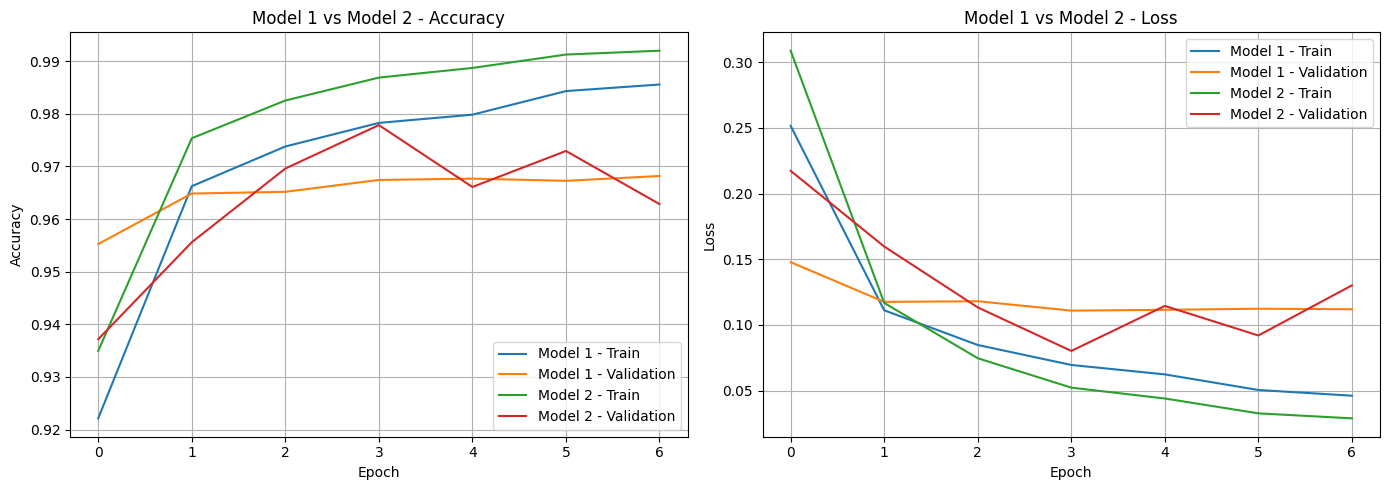

In [48]:
import matplotlib.pyplot as plt

# Extract histories
h1 = history1.history
h2 = history2.history

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# -------------------------------------------------
# Accuracy
# -------------------------------------------------
axes[0].plot(h1["acc"], label="Model 1 - Train")
axes[0].plot(h1["val_acc"], label="Model 1 - Validation")

axes[0].plot(h2["acc"], label="Model 2 - Train")
axes[0].plot(h2["val_acc"], label="Model 2 - Validation")

axes[0].set_title("Model 1 vs Model 2 - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# -------------------------------------------------
# Loss
# -------------------------------------------------
axes[1].plot(h1["loss"], label="Model 1 - Train")
axes[1].plot(h1["val_loss"], label="Model 1 - Validation")

axes[1].plot(h2["loss"], label="Model 2 - Train")
axes[1].plot(h2["val_loss"], label="Model 2 - Validation")

axes[1].set_title("Model 1 vs Model 2 - Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


> Model 1

Training accuracy increases roughly:

0.92 → 0.986

Validation accuracy:

starts around 0.954
rises to about 0.968
then stays almost completely flat around 0.967–0.968

That is actually quite stable. The final gap is approximately:

0.986−0.968≈0.0180.986 - 0.968 \approx 0.0180.986−0.968≈0.018

So there is a small train-validation gap, but validation performance is stable.

Model 2

Training accuracy increases:

0.935 → 0.993

Validation accuracy behaves differently:

starts around 0.952
reaches approximately 0.978 at epoch 3
falls to ~0.970
rises to ~0.976
finishes around 0.968

This is important.

Model 2 achieves the best validation accuracy, approximately 97.8% at epoch 3, but continuing training does not improve generalization.

By epoch 6:

Train≈99.3%Train \approx 99.3\%Train≈99.3%

while:

Validation≈96.8%Validation \approx 96.8\%Validation≈96.8%

That's a gap of roughly 2.5 percentage points.

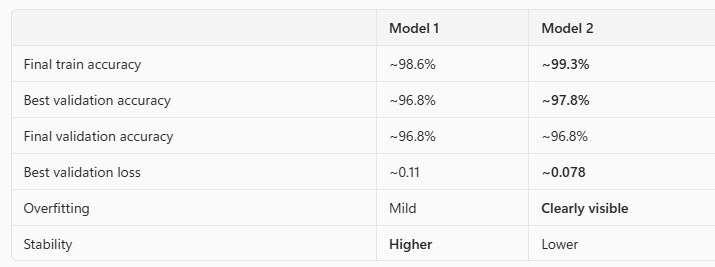
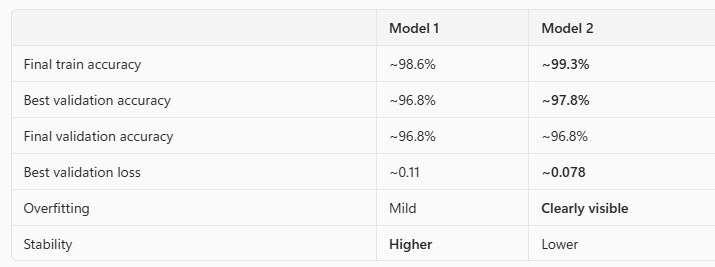

> Model 2 is overfitting.
> Model 1 is better and more stable. We see it in the training and validation curves.

# > *Model 3 based on Model 2 at best epock 3# ***

In [49]:
##################### TODO: CHANGE!
name_of_last_TL_layer = 'Conv_1'

In [50]:
!pip install -q keras-tuner

In [51]:
import keras
import keras_tuner as kt

In [52]:
def build_model3(hp):
    # Keep the pretrained base frozen
    base_model.trainable = False

    x = base_model.output

    # Same convolutional architecture as Model 2
    x = keras.layers.Conv2D(
        filters=256,
        kernel_size=(3, 3),
        padding="same",
        activation="relu",
        kernel_initializer="he_normal"
    )(x)

    x = keras.layers.MaxPool2D(
        pool_size=3,
        strides=2,
        padding="same"
    )(x)

    x = keras.layers.Conv2D(
        filters=256,
        kernel_size=(3, 3),
        padding="same",
        activation="relu",
        kernel_initializer="he_normal"
    )(x)

    x = keras.layers.MaxPool2D(
        pool_size=3,
        strides=2,
        padding="same"
    )(x)

    x = keras.layers.Flatten()(x)

    x = keras.layers.Dense(
        units=32,
        activation="relu",
        kernel_initializer="he_normal"
    )(x)

    x = keras.layers.BatchNormalization()(x)

    # Keras Tuner creates and supplies hp
    dropout_rate = hp.Choice(
        "dropout_rate",
        values=[0.2, 0.3, 0.4, 0.5]
    )

    x = keras.layers.Dropout(
        rate=dropout_rate
    )(x)

    x = keras.layers.Dense(
        units=10,
        activation="softmax"
    )(x)

    model = keras.models.Model(
        inputs=base_model.input,
        outputs=x,
        name="model3_dropout_tuning"
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

***Hyperparameters and summary***

In [53]:
hp = kt.HyperParameters()

model3_preview = build_model3(hp)

model3_preview.summary(show_trainable=True, line_length=100)

Model: "model3_dropout_tuning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ Layer (type)             ┃ Output Shape         ┃       Param # ┃ Connected to         ┃ Traina… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ input_layer (InputLayer) │ (None, 96, 96, 3)    │             0 │ -                    │    -    │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ Conv1 (Conv2D)           │ (None, 48, 48, 32)   │           864 │ input_layer[0][0]    │    N    │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ bn_Conv1                 │ (None, 48, 48, 32)   │           128 │ Conv1[0][0]          │    N    │
│ (BatchNormalization)     │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ Conv1_relu (ReLU)        │ (None, 48, 48, 32)   │             0 │ bn_Conv1[0][0]       │    -    │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ expanded_conv_depthwise  │ (None, 48, 48, 32)   │           288 │ Conv1_relu[0][0]     │    N    │
│ (DepthwiseConv2D)        │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ expanded_conv_depthwise… │ (None, 48, 48, 32)   │           128 │ expanded_conv_depth… │    N    │
│ (BatchNormalization)     │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ expanded_conv_depthwise… │ (None, 48, 48, 32)   │             0 │ expanded_conv_depth… │    -    │
│ (ReLU)                   │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ expanded_conv_project    │ (None, 48, 48, 16)   │           512 │ expanded_conv_depth… │    N    │
│ (Conv2D)                 │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ expanded_conv_project_BN │ (None, 48, 48, 16)   │            64 │ expanded_conv_proje… │    N    │
│ (BatchNormalization)     │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block_1_expand (Conv2D)  │ (None, 48, 48, 96)   │         1,536 │ expanded_conv_proje… │    N    │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block_1_expand_BN        │ (None, 48, 48, 96)   │           384 │ block_1_expand[0][0] │    N    │
│ (BatchNormalization)     │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block_1_expand_relu      │ (None, 48, 48, 96)   │             0 │ block_1_expand_BN[0… │    -    │
│ (ReLU)                   │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block_1_pad              │ (None, 49, 49, 96)   │             0 │ block_1_expand_relu… │    -    │
│ (ZeroPadding2D)          │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block_1_depthwise        │ (None, 24, 24, 96)   │           864 │ block_1_pad[0][0]    │    N    │
│ (DepthwiseConv2D)        │                      │          

 Total params: 5,806,122 (22.15 MB)

 Trainable params: 3,548,074 (13.53 MB)

 Non-trainable params: 2,258,048 (8.61 MB)

**Build the Hyperparameter tuner**

In [54]:
tuner = kt.RandomSearch(
    hypermodel=build_model3,
    objective="val_loss",
    max_trials=4,
    executions_per_trial=1,
    overwrite=True,
    directory="/kaggle/working/model3_tuning",
    project_name="dropout_tuning",
    seed=42
)

**TRAINING WITH TUNER**

In [55]:
tuner.search(
    ds_train,
    validation_data=ds_val,
    epochs=7
)

Trial 4 Complete [00h 02m 09s]
val_loss: 0.13852174580097198

Best val_loss So Far: 0.10856147110462189
Total elapsed time: 00h 08m 25s


In [65]:
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]

print(
    "Best dropout rate:",
    best_hps.get("dropout_rate")
)
best_dropout = best_hps.get("dropout_rate")

Best dropout rate: 0.4


**Build the actual final Model 3**

In [57]:
model3 = build_model3(best_hps)

model3.summary()

Model: "model3_dropout_tuning"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 96, 96, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 48, 48,    │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 48, 48,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 48, 48,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 48, 48,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 48, 48,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 48, 48,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 48, 48,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 48, 48,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 48, 48,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 48, 48,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 48, 48,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 49, 49,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 24, 24,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 24, 24,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 24, 24,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 24, 24,    │      2,304 │ block_1_depthwis

 Total params: 5,806,122 (22.15 MB)

 Trainable params: 3,548,074 (13.53 MB)

 Non-trainable params: 2,258,048 (8.61 MB)

In [58]:
history3 = model3.fit(
    ds_train,
    validation_data=ds_val,
    epochs=7
)

Epoch 1/7
375/375 ━━━━━━━━━━━━━━━━━━━━ 30s 51ms/step - accuracy: 0.8224 - loss: 0.6676 - val_accuracy: 0.8668 - val_loss: 0.4645
Epoch 2/7
375/375 ━━━━━━━━━━━━━━━━━━━━ 15s 37ms/step - accuracy: 0.9628 - loss: 0.1560 - val_accuracy: 0.9459 - val_loss: 0.1782
Epoch 3/7
375/375 ━━━━━━━━━━━━━━━━━━━━ 15s 37ms/step - accuracy: 0.9803 - loss: 0.0812 - val_accuracy: 0.9632 - val_loss: 0.1253
Epoch 4/7
375/375 ━━━━━━━━━━━━━━━━━━━━ 15s 37ms/step - accuracy: 0.9866 - loss: 0.0532 - val_accuracy: 0.9617 - val_loss: 0.1639
Epoch 5/7
375/375 ━━━━━━━━━━━━━━━━━━━━ 15s 37ms/step - accuracy: 0.9911 - loss: 0.0360 - val_accuracy: 0.9699 - val_loss: 0.1178
Epoch 6/7
375/375 ━━━━━━━━━━━━━━━━━━━━ 15s 37ms/step - accuracy: 0.9928 - loss: 0.0268 - val_accuracy: 0.9767 - val_loss: 0.0942
Epoch 7/7
375/375 ━━━━━━━━━━━━━━━━━━━━ 15s 38ms/step - accuracy: 0.9953 - loss: 0.0185 - val_accuracy: 0.9735 - val_loss: 0.1167


In [59]:
history3.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

In [60]:
print(history3.history["accuracy"])
print(history3.history["val_accuracy"])
print(history3.history["loss"])
print(history3.history["val_loss"])

[0.9040208458900452, 0.9666666388511658, 0.9806874990463257, 0.9863958358764648, 0.9904166460037231, 0.9928958415985107, 0.9950416684150696]
[0.8668333292007446, 0.9459166526794434, 0.9632499814033508, 0.9617499709129333, 0.9699166417121887, 0.9766666889190674, 0.9735000133514404]
[0.39897334575653076, 0.13839417695999146, 0.07654846459627151, 0.051206231117248535, 0.03731813654303551, 0.026994936168193817, 0.018887104466557503]
[0.46446025371551514, 0.17817051708698273, 0.12531563639640808, 0.1639489382505417, 0.11780167371034622, 0.09420455992221832, 0.11667705327272415]


In [61]:
# Evaluate
val_loss, val_acc = model3.evaluate(ds_val)
print(f'Val accuracy OF MODEL 3: {val_acc:.3f}') # gives %
print(f'Val loss OF MODEL 3: {val_loss:.3f}') # gives %

94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.9758 - loss: 0.1097
Val accuracy OF MODEL 3: 0.974
Val loss OF MODEL 3: 0.117


**ALL 3 MODELS PLOTS**

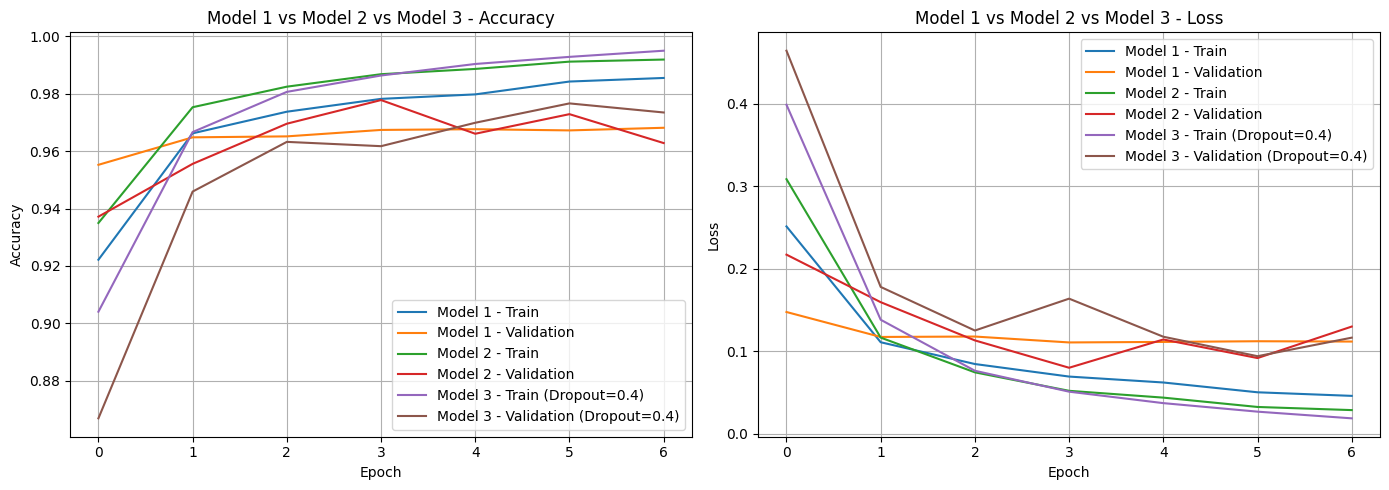

In [66]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

# =========================
# Accuracy
# =========================
plt.subplot(1, 2, 1)

# Model 1
plt.plot(history1.history['acc'],
         label='Model 1 - Train')
plt.plot(history1.history['val_acc'],
         label='Model 1 - Validation')

# Model 2
plt.plot(history2.history['acc'],
         label='Model 2 - Train')
plt.plot(history2.history['val_acc'],
         label='Model 2 - Validation')

# Model 3
plt.plot(history3.history['accuracy'],
         label=f'Model 3 - Train (Dropout={best_dropout})')
plt.plot(history3.history['val_accuracy'],
         label=f'Model 3 - Validation (Dropout={best_dropout})')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Model 1 vs Model 2 vs Model 3 - Accuracy')
plt.legend()
plt.grid(True)


# =========================
# Loss
# =========================
plt.subplot(1, 2, 2)

# Model 1
plt.plot(history1.history['loss'],
         label='Model 1 - Train')
plt.plot(history1.history['val_loss'],
         label='Model 1 - Validation')

# Model 2
plt.plot(history2.history['loss'],
         label='Model 2 - Train')
plt.plot(history2.history['val_loss'],
         label='Model 2 - Validation')

# Model 3
plt.plot(history3.history['loss'],
         label=f'Model 3 - Train (Dropout={best_dropout})')
plt.plot(history3.history['val_loss'],
         label=f'Model 3 - Validation (Dropout={best_dropout})')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Model 1 vs Model 2 vs Model 3 - Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [74]:
import numpy as np

def summarize_history(name, history):
    h = history.history

    best_acc_epoch = np.argmax(h['val_acc'])
    best_loss_epoch = np.argmin(h['val_loss'])

    print(f"\n{name}")
    print("-" * 40)

    print(
        f"Best val accuracy: "
        f"{h['val_acc'][best_acc_epoch]:.4f} "
        f"(epoch {best_acc_epoch + 1})"
    )

    print(
        f"Best val loss: "
        f"{h['val_loss'][best_loss_epoch]:.4f} "
        f"(epoch {best_loss_epoch + 1})"
    )

    print(
        f"Train accuracy at best val-loss epoch: "
        f"{h['acc'][best_loss_epoch]:.4f}"
    )

    print(
        f"Val accuracy at best val-loss epoch: "
        f"{h['val_acc'][best_loss_epoch]:.4f}"
    )

    print(
        f"Accuracy gap: "
        f"{h['acc'][best_loss_epoch] - h['val_acc'][best_loss_epoch]:.4f}"
    )

def summarize_history3(name, history):
    h = history.history

    best_acc_epoch = np.argmax(h['val_accuracy'])
    best_loss_epoch = np.argmin(h['val_loss'])

    print(f"\n{name}")
    print("-" * 40)

    print(
        f"Best val accuracy: "
        f"{h['val_accuracy'][best_acc_epoch]:.4f} "
        f"(epoch {best_acc_epoch + 1})"
    )

    print(
        f"Best val loss: "
        f"{h['val_loss'][best_loss_epoch]:.4f} "
        f"(epoch {best_loss_epoch + 1})"
    )

    print(
        f"Train accuracy at best val-loss epoch: "
        f"{h['accuracy'][best_loss_epoch]:.4f}"
    )

    print(
        f"Val accuracy at best val-loss epoch: "
        f"{h['val_accuracy'][best_loss_epoch]:.4f}"
    )

    print(
        f"Accuracy gap: "
        f"{h['accuracy'][best_loss_epoch] - h['val_accuracy'][best_loss_epoch]:.4f}"
    )

summarize_history("Model 1", history1)
summarize_history("Model 2", history2)
summarize_history3("Model 3 (Dropout=0.4)", history3)


Model 1
----------------------------------------
Best val accuracy: 0.9682 (epoch 7)
Best val loss: 0.1109 (epoch 4)
Train accuracy at best val-loss epoch: 0.9783
Val accuracy at best val-loss epoch: 0.9674
Accuracy gap: 0.0108

Model 2
----------------------------------------
Best val accuracy: 0.9778 (epoch 4)
Best val loss: 0.0802 (epoch 4)
Train accuracy at best val-loss epoch: 0.9869
Val accuracy at best val-loss epoch: 0.9778
Accuracy gap: 0.0090

Model 3 (Dropout=0.4)
----------------------------------------
Best val accuracy: 0.9767 (epoch 6)
Best val loss: 0.0942 (epoch 6)
Train accuracy at best val-loss epoch: 0.9929
Val accuracy at best val-loss epoch: 0.9767
Accuracy gap: 0.0162


# Evaluate
test_loss, test_acc = model.evaluate(test_ds)
print(f'Test accuracy: {test_acc:.3f}')

## Uppgift
Notera antal parametrar som tränats, testnoggrannhet, körtid
(Notera att en noggrannhet på 91.5% är minimum för denna laboration!)

Vad kan man dra för slutsatser av dina körningar i denna del?

### STUDENTSVAR (Analys):

## Uppgift
När du nu funnit de bästa "topplagren" du kan finna, utvärdera din överförda model även med följande variationer:
* bildstorlek: utvärdera med följande bildstorlekar: minimistorlek, 28\*2x28\*2,  28\*3x28\*3.

Notera antal parametrar som tränats, testnoggrannhet, körtid

Vad kan man dra för slutsatser av detta?


### STUDENTSVAR (Analys):

# Del B

För överförd inlärning med VGG enligt ovan så ska du här slå på träning även för några av de importerade lagren och utvärdera hur det påverkar modellens prestanda. Lämpligen slår du först på alla lager för träning: "model.trainable = True". Om du sedan inte vill träna alla lager så kan du loopa över alla lager och göra "layer.trainable = False" där/om så behövs.
Notera att du kan lätt se vilka lager som är träningsbara mha `model.summary(show_trainable=True)`

Notera att du nog bör minska inlärningstakten (till typ 1e-4 -- 1e-5 för Adam) när du även tränar den överförda modellens parametrar, för annars kan den "glömma" för mycket av den förtränade modellen och modellen kan rent av bli sämre.

### STUDENTSVAR (KOD)

In [ ]:
# Kod för del B

## Analys
Analysera vilken betydelse hur stor del av den överförda modellen som tränas (prestanda, träningsförlopp, körtiden)

### STUDENTSVAR (ANALYS):


# Del X (VG uppgift)

För denna deluppgift ska du ersätta VGG16 med Xception https://keras.io/api/applications/xception/ som bas för överförd inlärning och utvärdera den resulterande modellen på vårt Fashion-MNIST problem. Notera att Xception har en annan storlek som minsta möjliga storlek för inbilderna. Vi behöver även ändra normaliseringen då Xception vill ha RGB i området -1.0 till 1.0. Då modellen har 126 lager så kommer vi bara använda en del av alla dess lager på våra små bilder. Välj ett lämplig antal lager av Xceptionmodellen och motivera varför du inte använder fler. Utvärdera Xception och jämför med när du använde VGG16.

### STUDENTSVAR (VG KOD)

In [ ]:
# Kod för del X

## Analys

Utvärdera Xception och jämför med när du använde VGG16.

### STUDENTSVAR (VG ANALYS):


# För Alla Delar
Sammanställ dina resultat och gör en analys om hur de olika modellerna beter sig, speciellt mellan de modeller du har prövat i denna laboration, men även mot dina resultat i Laboration 1.

### STUDENTSVAR (ANALYS):


# AI Deklaration
Användning av Al-verktyg är "tillåtet", men vi vill se kommentar i koden, där det har använts för att skapa hela block av kod.

Här på slutet ska du ange allmänt vilka AI-verktyg som använts, hur du använt dem, och hur användbara dessa verktyg är. Om du inte använt AI-stöd så skriv bara att "AI-verktyg har ej använts".

### STUDENTSVAR (AI-användning):